[3.1] Используя функцию multivariate_normal (numpy) с любым random_state,
сгенерировать датасет df1, в котором есть три класса с размером каждого класса 100
объектов и 16 количественных (недискретных) признаков. Распределения двух из трех
классов должны значительно перекрывать друг друга, тогда как третий класс должен
быть на расстоянии от первых двух классов.
### Не забываем повторять шаги задания 1:
- ключевые характеристики датасета - корреляции
- визуализация панно scatterplot на всех парах переменных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.discriminant_analysis import (
        LinearDiscriminantAnalysis,
        QuadraticDiscriminantAnalysis
    )
from sklearn.naive_bayes import GaussianNB
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

/Users/evabankeeva/Study/statistical-decision-theory/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
np.random.seed(42)

n_features = 16
n_objects = 100

mean1 = np.zeros(n_features)
mean2 = np.ones(n_features) * 0.8
mean3 = np.ones(n_features) * 5

cov = np.eye(n_features)

class1 = np.random.multivariate_normal(mean1, cov, n_objects)
class2 = np.random.multivariate_normal(mean2, cov, n_objects)
class3 = np.random.multivariate_normal(mean3, cov, n_objects)

X = np.vstack([class1, class2, class3])

y = np.repeat([0, 1, 2], n_objects)

df1 = pd.DataFrame(
    X,
    columns=[f'feature_{i}' for i in range(16)]
)

df1['class'] = y
df1

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,class
0,0.496714,-0.138264,0.647689,1.523030,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,-0.463418,-0.465730,0.241962,-1.913280,-1.724918,-0.562288,0
1,-1.012831,0.314247,-0.908024,-1.412304,1.465649,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,-0.601707,1.852278,0
2,-0.013497,-1.057711,0.822545,-1.220844,0.208864,-1.959670,-1.328186,0.196861,0.738467,0.171368,-0.115648,-0.301104,-1.478522,-0.719844,-0.460639,1.057122,0
3,0.343618,-1.763040,0.324084,-0.385082,-0.676922,0.611676,1.031000,0.931280,-0.839218,-0.309212,0.331263,0.975545,-0.479174,-0.185659,-1.106335,-1.196207,0
4,0.812526,1.356240,-0.072010,1.003533,0.361636,-0.645120,0.361396,1.538037,-0.035826,1.564644,-2.619745,0.821903,0.087047,-0.299007,0.091761,-1.987569,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,6.007157,5.517995,5.026205,4.696436,4.919083,1.829574,5.210601,4.511524,6.592670,5.019344,3.811037,4.950120,3.953879,5.473407,5.290947,5.957840,2
296,4.209118,5.034008,3.634978,5.701495,5.518871,5.495805,5.001619,5.414773,6.604339,4.714906,5.138645,3.913874,4.131739,5.097813,6.103934,4.743719,2
297,4.764083,4.593115,4.465243,5.294971,3.502742,6.280940,4.334578,5.721903,3.730001,5.668840,5.671945,5.384202,4.005571,5.249548,3.816944,4.747237,2
298,6.029413,5.796702,5.015183,4.025193,5.645588,5.019381,2.679684,5.782630,4.975767,6.202451,3.904729,1.823296,5.279084,5.291564,3.309328,4.021500,2


In [3]:
def statistics_table(df):
    summary_df = pd.DataFrame({
        'dtype':         df.dtypes.astype(str),
        'Уникальных':    df.nunique(),
        'Пропусков':     df.isna().sum(),
        'Мода уровня 1':          df.mode().iloc[0],
        'Среднее':       df.mean(),
        'Медиана':       df.median(),
        'Стд.откл.':     df.std(),
        'Дисперсия':     df.var(),
        'Мин':           df.min(),
        'Макс':          df.max(),
        'Размах':        df.max() - df.min(),
        'IQR':           (df.quantile(0.75, )
                        - df.quantile(0.25, )),
        'Асимметрия':    df.skew(),
        'Эксцесс':       df.kurt()
    })

    return summary_df

statistics_table(df1)

,dtype,Уникальных,Пропусков,Мода уровня 1,Среднее,Медиана,Стд.откл.,Дисперсия,Мин,Макс,Размах,IQR,Асимметрия,Эксцесс
feature_0,float64,300,0,-2.471645,1.922785,1.106854,2.340432,5.477620,-2.471645,7.755218,10.226862,3.920641,5.229569e-01,-0.943813
feature_1,float64,300,0,-2.423879,1.943295,1.237450,2.304027,5.308541,-2.423879,7.511557,9.935436,3.762296,5.262944e-01,-0.850506
feature_2,float64,300,0,-2.553921,1.855503,1.084665,2.319780,5.381379,-2.553921,7.049812,9.603733,4.238894,5.347736e-01,-1.006755
feature_3,float64,300,0,-2.872262,1.908656,1.057853,2.344537,5.496852,-2.872262,6.629166,9.501429,4.168997,4.375284e-01,-1.111963
feature_4,float64,300,0,-2.081929,2.030532,1.086035,2.512807,6.314200,-2.081929,8.243093,10.325022,4.571817,5.378540e-01,-1.089877
feature_5,float64,300,0,-2.848543,1.909544,1.222286,2.391941,5.721380,-2.848543,7.307916,10.156459,4.260603,4.690071e-01,-1.042782
feature_6,float64,300,0,-3.241267,1.919934,1.145794,2.407593,5.796505,-3.241267,7.485190,10.726457,4.320993,4.558139e-01,-1.001370
feature_7,float64,300,0,-2.921350,1.976199,1.121347,2.440364,5.955378,-2.921350,7.320041,10.241391,4.463557,4.699878e-01,-1.128537
feature_8,float64,300,0,-2.499406,1.923473,1.078460,2.513554,6.317955,-2.499406,7.303639,9.803044,4.554353,4.908673e-01,-1.117671
feature_9,float64,300,0,-2.152891,1.953986,1.217780,2.322260,5.392892,-2.152891,7.868403,10.021294,4.126100,4.797584e-01,-1.055031


In [4]:
def plot_correlation(df, title='Корреляционная матрица', target=None):
    df = df.select_dtypes(include='number')

    if target is not None:
        df = df.drop(columns=[target], errors='ignore')

    corr = df.corr(method='pearson')

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        cmap='RdBu_r',
        vmin=-1,
        vmax=1,
        center=0,
        square=True
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

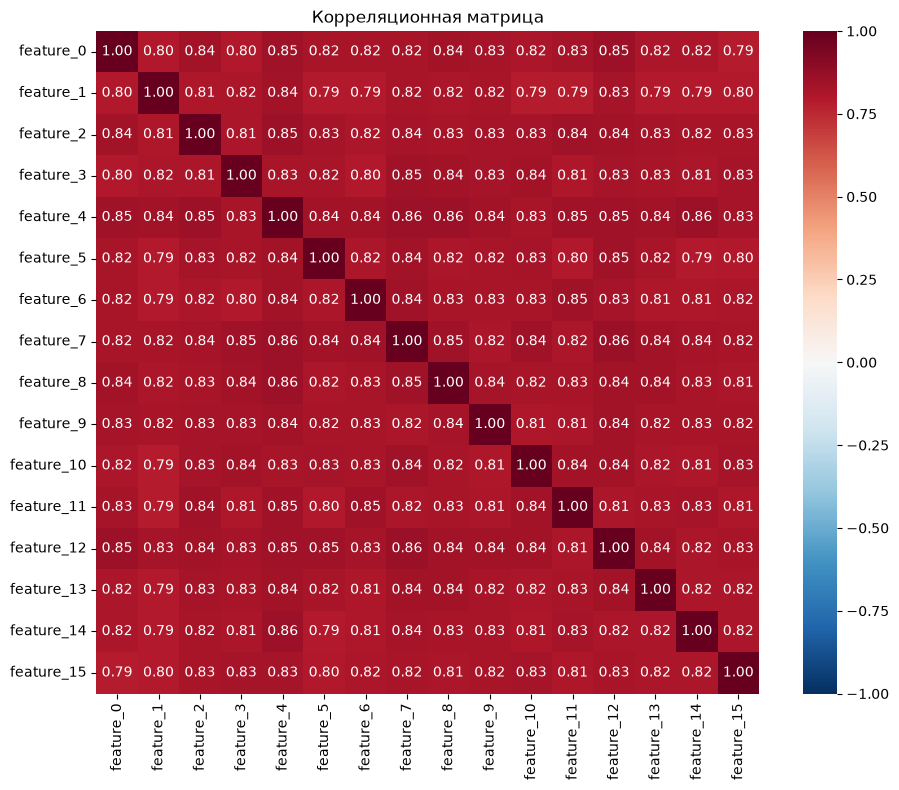

In [5]:
plot_correlation(df1, target='class')

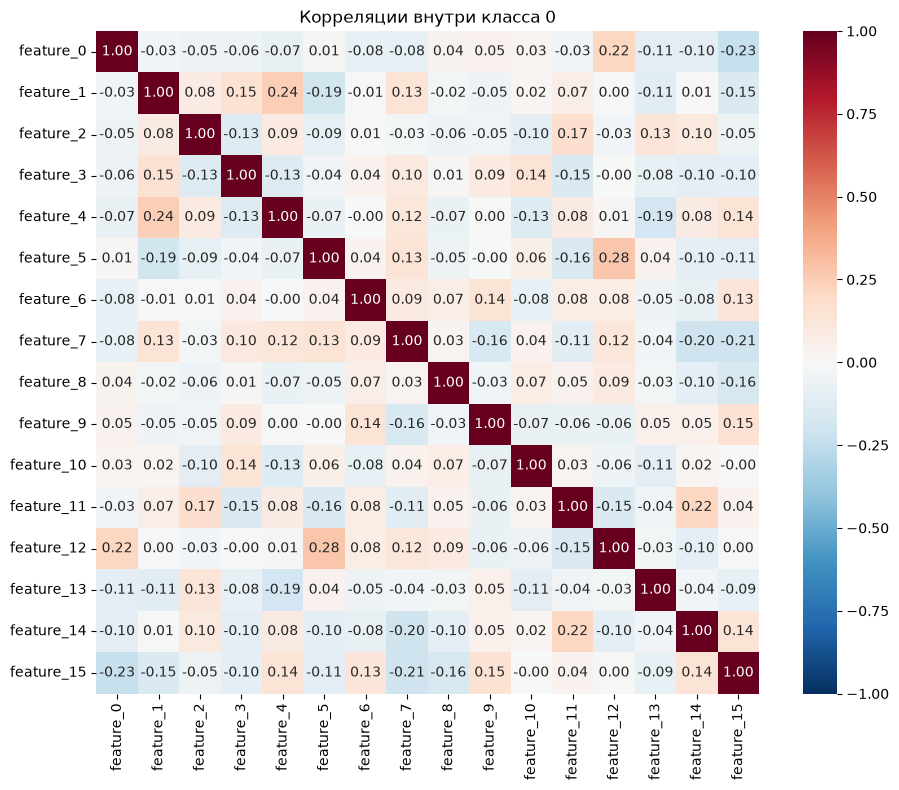

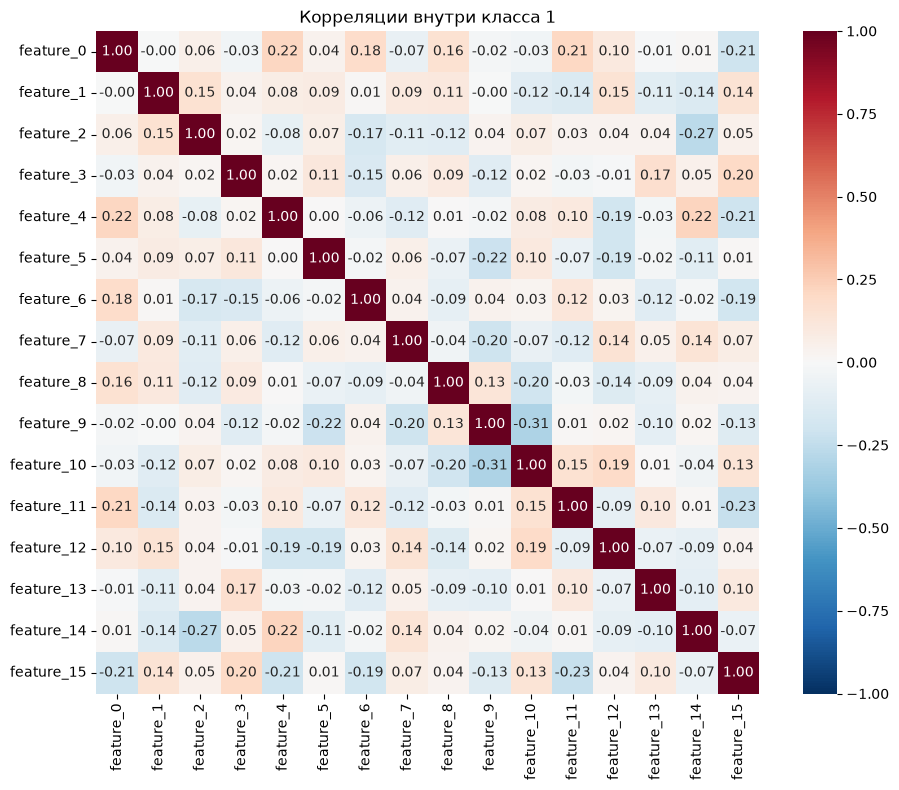

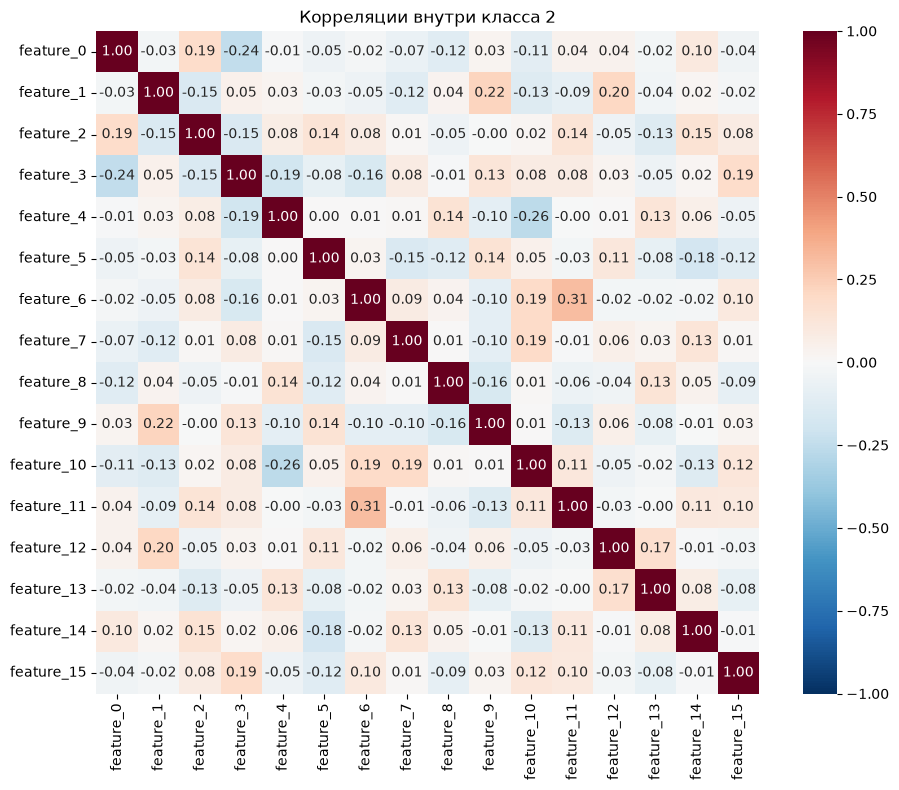

In [6]:
for c in [0, 1, 2]:
    plot_correlation(
        df1[df1['class'] == c],
        title=f'Корреляции внутри класса {c}',
        target='class'
    )

In [7]:
def scatterplot(
    df,
    features=None,
    class_col='quality',
    classes=None,
    show_regression=True,
    show_confidence=True,
    show_prediction=True,
    max_features=None,
    figsize=None,
):

    if class_col not in df.columns:
        raise ValueError(
            f"Колонка '{class_col}' не найдена. "
            f"Доступные: {list(df.columns)}"
        )

    if features is None:
        features = [
            c for c in df.select_dtypes(include='number').columns
            if c != class_col
        ]
    else:
        features = list(features)
        missing = [f for f in features if f not in df.columns]
        if missing:
            raise ValueError(f"Признаки не найдены в DataFrame: {missing}")

    if not features:
        raise ValueError("Не найдено ни одного числового признака для отображения.")

    if max_features is not None and len(features) > max_features:
        print(f"Признаков {len(features)}, показываю первые {max_features}.")
        features = features[:max_features]

    if classes is None:
        classes = sorted(df[class_col].dropna().unique())
    classes = list(classes)

    palette = [
        "#6453C5", "#58B85D", "#E87950",
        "#F2C14E", "#4EA5D9", "#B33F62",
        "#7FB069", "#E26D5C", "#5B8E7D", "#8B5A96",
    ]
    colors = [palette[k % len(palette)] for k in range(len(classes))]

    n = len(features)
    if figsize is None:
        side = max(8.0, 3.5 * n)
        figsize = (side, side)

    fig, axes = plt.subplots(n, n, figsize=figsize)

    if n == 1:
        axes = np.array([[axes]])

    for i, y_feature in enumerate(features):
        for j, x_feature in enumerate(features):
            ax = axes[i, j]

            if i == j:
                for k, cls in enumerate(classes):
                    data = df.loc[
                        df[class_col] == cls,
                        x_feature
                    ].dropna()

                    if len(data) == 0:
                        continue

                    sns.kdeplot(
                        data=data,
                        ax=ax,
                        color=colors[k],
                        linewidth=2,
                        fill=True,
                        alpha=0.25,
                        label=f'Класс {cls}'
                    )

                ax.set_xlabel('')
                ax.set_ylabel('')
                ax.set_title(x_feature, fontsize=12, fontweight='bold')
                ax.grid(True, alpha=0.25)

            else:
                n_cell = len(df[[x_feature, y_feature]].dropna())
                point_alpha = min(0.9, max(0.35, 200 / max(1, n_cell)))

                for k, cls in enumerate(classes):
                    data = df[
                        df[class_col] == cls
                    ][[x_feature, y_feature]].dropna()

                    x = data[x_feature].values
                    y = data[y_feature].values
                    n_cls = len(data)

                    if n_cls == 0:
                        continue

                    ax.scatter(
                        x, y,
                        color=colors[k],
                        marker='o',
                        s=25,
                        alpha=point_alpha
                    )

                    if n_cls < 3:
                        continue

                    slope, intercept, r_value, p_value, std_err = \
                        stats.linregress(x, y)

                    x_pred = np.linspace(x.min(), x.max(), 200)
                    y_pred = intercept + slope * x_pred
                    n_points = len(x)
                    x_mean = np.mean(x)

                    residuals = y - (intercept + slope * x)
                    s_err = np.sqrt(np.sum(residuals ** 2) / (n_points - 2))

                    t_value = stats.t.ppf(0.975, n_points - 2)
                    x_variance = np.sum((x - x_mean) ** 2)

                    if x_variance == 0:
                        continue

                    confidence = (
                        t_value * s_err
                        * np.sqrt(1 / n_points
                                  + (x_pred - x_mean) ** 2 / x_variance)
                    )
                    prediction = (
                        t_value * s_err
                        * np.sqrt(1
                                  + 1 / n_points
                                  + (x_pred - x_mean) ** 2 / x_variance)
                    )

                    if show_prediction:
                        ax.fill_between(
                            x_pred, y_pred - prediction, y_pred + prediction,
                            color=colors[k], alpha=0.08
                        )
                    if show_confidence:
                        ax.fill_between(
                            x_pred, y_pred - confidence, y_pred + confidence,
                            color=colors[k], alpha=0.20
                        )
                    if show_regression:
                        ax.plot(x_pred, y_pred, color=colors[k], linewidth=2)

                ax.grid(True, alpha=0.25)

            if i == n - 1:
                ax.set_xlabel(x_feature, fontsize=11, fontweight='bold')
            else:
                ax.set_xlabel('')

            if i == 0:
                ax.set_title(x_feature, fontsize=11, fontweight='bold')

            if j == 0:
                ax.set_ylabel(y_feature, fontsize=11, fontweight='bold')
            else:
                ax.set_ylabel('')

            if j == n - 1:
                ax.yaxis.set_label_position('right')
                ax.set_ylabel(y_feature, fontsize=11, fontweight='bold')

    handles = [
        plt.Line2D(
            [0], [0],
            marker='o',
            color='w',
            markerfacecolor=colors[k],
            markersize=10,
            label=f'Класс {cls}'
        )
        for k, cls in enumerate(classes)
    ]

    fig.legend(
        handles=handles,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),
        ncol=len(classes),
        fontsize=18,
        frameon=True,
        title='Классы',
        title_fontsize=18,
    )

    fig.suptitle(
        'Визуализация выбранных признаков по классам',
        fontsize=20,
        fontweight='bold',
        y=0.99
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

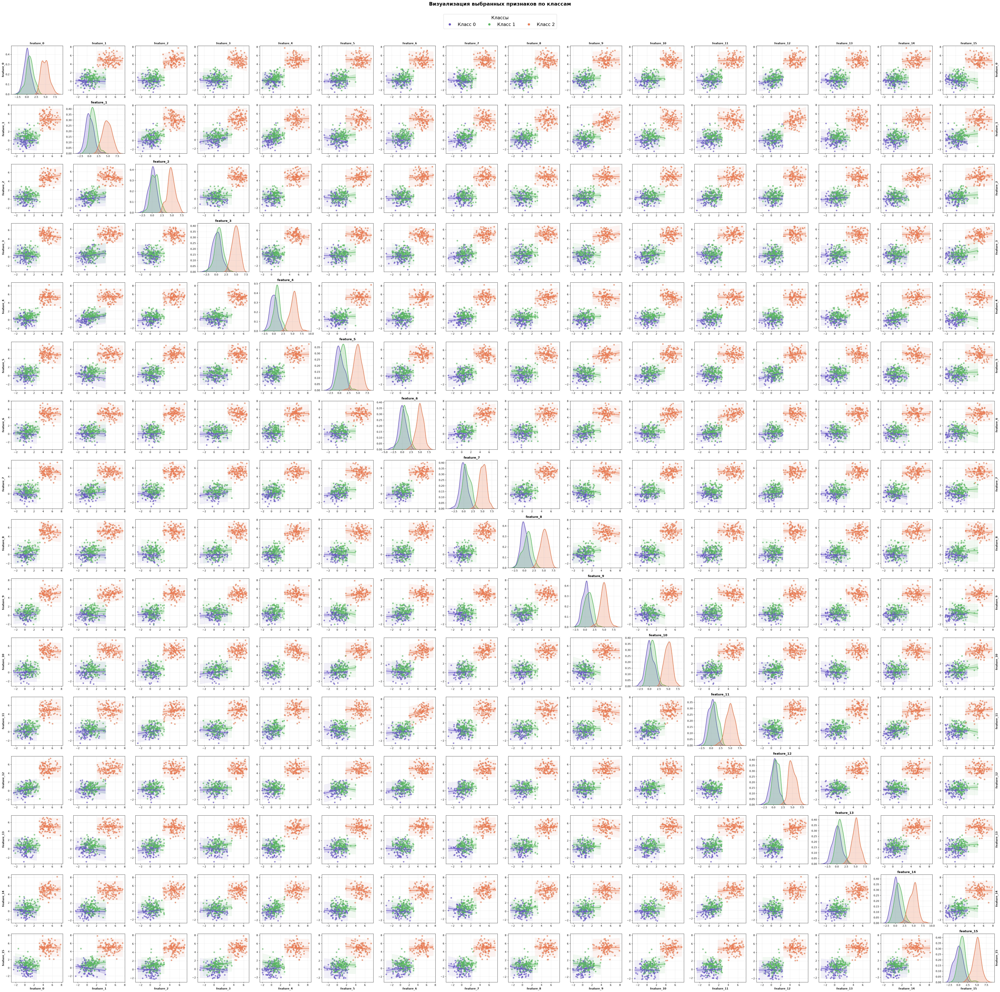

In [8]:
scatterplot(df1, 
            class_col='class',
            show_regression=True,
            show_confidence=True,
            show_prediction=True
            )

[3.2] На основе созданного в пункте [3.1] датасета df1 сгенерировать отдельные
дополнительные датасеты (dfrX), в которых объекты одного класса (который имеет
пересечение с другим) повторены X раз (Х=1, 2, 5, 10, 100, 1000 раз, с учетом исходного),
а количество объектов в остальных классах оставлено неизменным.
Отдельно для датасетов dfrX восстановить в таблицу координаты следующих точек:
- центры масс каждого класса; 
- общий центр масс выбранных классов;
- центр отрезка, соединяющего центры масс выбранных классов.

In [9]:
X_values = [1, 2, 5, 10, 100, 1000]
datasets = {}

for X in X_values:
    repeated_class = df1[df1['class'] == 0]
    repeated_objects = pd.concat([repeated_class] * X, ignore_index=True)
    other_objects = df1[df1['class'] != 0]

    dfrX = pd.concat(
        [repeated_objects, other_objects],
        ignore_index=True
    )

    datasets[X] = dfrX

In [10]:
results = []
feature_cols = [col for col in df1.columns if col != 'class']
selected_classes = [0, 1]

for X, dfrX in datasets.items():

    class_centers = {}

    for cls in sorted(dfrX['class'].unique()):
        center = dfrX.loc[
            dfrX['class'] == cls, feature_cols
        ].mean().to_numpy()

        class_centers[cls] = center

        results.append({
            'X': X,
            'point': f'Центр класса {cls}',
            **dict(zip(feature_cols, center))
        })
    selected_data = dfrX[
        dfrX['class'].isin(selected_classes)
    ]

    common_center = selected_data[feature_cols].mean().to_numpy()

    results.append({
        'X': X,
        'point': 'Общий центр классов 0 и 1',
        **dict(zip(feature_cols, common_center))
    })
    center_segment = (
        class_centers[selected_classes[0]]
        + class_centers[selected_classes[1]]
    ) / 2

    results.append({
        'X': X,
        'point': 'Середина между центрами классов 0 и 1',
        **dict(zip(feature_cols, center_segment))
    })
coordinates = pd.DataFrame(results)
coordinates = coordinates.set_index(['X', 'point'])
coordinates

feature_0  feature_1  feature_2  \
X    point                                                                    
1    Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.437133   0.526360   0.369862   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   
2    Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.320809   0.372827   0.265884   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   
5    Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.204485   0.219293   0.161905   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   
10   Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.151610   0.149505   0.114642   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   
100  Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.095071   0.074880   0.064104   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   
1000 Центр класса 0                          0.088161   0.065760   0.057927   
     Центр класса 1                          0.786105   0.986961   0.681797   
     Центр класса 2                          4.894089   4.777164   4.826784   
     Общий центр классов 0 и 1               0.088858   0.066680   0.058550   
     Середина между центрами классов 0 и 1   0.437133   0.526360   0.369862   

                                            feature_3  feature_4  feature_5  \
X    point                                                                    
1    Центр класса 0                          0.163494  -0.030166   0.022045   
     Центр класса 1                          0.664233   0.828902   0.769837   
     Центр класса 2                          4.898241   5.292859   4.936750   
     Общий центр классов 0 и 1               0.413864   0.399368   0.395941   
     Середина между центрами классов 0 и 1   0.413864   0.399368   0.395941   
2    Центр класса 0                          0.163494  -0.030166   0.022045   
     Центр класса 1                          0.664233   0.828902   0.769837   
     Центр класса 2                          4.898241   5.292859   4.936750   
     Общий центр классов 0 и 1               0.330407   0.256190   0.271309   
     Середина между центрами классов 0 и 1   0.413864   0.399368   0.395941   
5    Центр класса 0                          0.163494  -0.030166   0.022045   
     Центр класса 1                          0.664233   0.828902   0.769837   
     Центр класса 2                          4.898241   5.292859   4.936750   
     Общий центр классов 0 и 1               0.246951   0.113012   0.146677   
     Середина между центрами классов 0 и 1   0.413864   0.399368   0.395941   
10   Центр класса 0                          0.163494  -0.030166   0.022045   
     Центр класса 1                          0.664233   0.828902   0.769837   
     Центр кла

[3.3] Выбрать пару классов (включая класс с повторенными объектами) и пару
количественных признаков, определить в паре целевой класс. Используя методы LDA,
QDA, Gaussian Naïve Bayes, MDC для каждого из сформированных датасетов dfrX,
графически в виде панно Х (датасет dfrX) на Y (метод) для каждой пары датасет-
алгоритм построить индивиуальные графики с решающей функцией, разграниченные
решающей линий решающей функции зоны и отдельные объекты классов. Визуализацию
выполнять с отображением положения центров масс и соединяющего центры масс
классов отрезок с его центральной точкой на каждом графике.

In [11]:
def plot_decision_panels(
    datasets,
    selected_classes,
    features,
    methods=('LDA', 'QDA', 'Gaussian Naive Bayes', 'MDC'),
    class_col='class',
    figsize=None,
    grid_size=250,
    show_global_center=True
):
    colors = {
        0: '#6453C5',
        1: '#3B7E3F',
        2: "#E8D907"
    }
    region_colors = ['#DCD6F7', '#D5F0D5', "#FFEE7E"]

    n_rows = len(datasets)
    n_cols = len(methods)

    if figsize is None:
        figsize = (4 * n_cols, 3.8 * n_rows)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=figsize,
        squeeze=False
    )

    progress = tqdm(total=n_rows * n_cols, desc='Построение графиков')

    try:
        for row, (X, dfrX) in enumerate(datasets.items()):
            data = dfrX[
                dfrX[class_col].isin(selected_classes)
            ][features + [class_col]].dropna()

            X_data = data[features].to_numpy()
            y_data = data[class_col].to_numpy()

            centers = {
                cls: data.loc[
                    data[class_col] == cls, features
                ].mean().to_numpy()
                for cls in selected_classes
            }

            midpoint = (
                centers[selected_classes[0]]
                + centers[selected_classes[1]]
            ) / 2

            global_center = data[features].mean().to_numpy()

            x_min, x_max = data[features[0]].min(), data[features[0]].max()
            y_min, y_max = data[features[1]].min(), data[features[1]].max()

            x_center = (x_min + x_max) / 2
            y_center = (y_min + y_max) / 2

            half_range = max(
                (x_max - x_min) / 2,
                (y_max - y_min) / 2
            ) * 1.5

            xx, yy = np.meshgrid(
                np.linspace(x_center - half_range, x_center + half_range, grid_size),
                np.linspace(y_center - half_range, y_center + half_range, grid_size)
            )

            grid = np.c_[xx.ravel(), yy.ravel()]

            n_objects = len(data)
            point_alpha = np.clip(
                0.5 / np.sqrt(n_objects / 300),
                0.15,
                0.7
            )

            for col, method in enumerate(methods):
                ax = axes[row, col]

                if method == 'LDA':
                    model = LinearDiscriminantAnalysis()
                elif method == 'QDA':
                    model = QuadraticDiscriminantAnalysis()
                elif method == 'Gaussian Naive Bayes':
                    model = GaussianNB()
                elif method == 'Linear SVM':
                    model = SVC(kernel='linear')
                elif method == 'LogReg':
                    model = LogisticRegression(max_iter=1000)
                elif method == 'MDC':
                    model = None
                else:
                    raise ValueError(f'Неизвестный метод: {method}')

                if method != 'MDC':
                    model.fit(X_data, y_data)
                    predictions = model.predict(grid)
                else:
                    distances = np.column_stack([
                        np.sum((grid - centers[cls]) ** 2, axis=1)
                        for cls in selected_classes
                    ])

                    predictions = np.array(selected_classes)[
                        np.argmin(distances, axis=1)
                    ]


                Z = predictions.reshape(xx.shape)

                Z_encoded = np.zeros_like(Z, dtype=int)

                for i, cls in enumerate(selected_classes):
                    Z_encoded[Z == cls] = i

                ax.contourf(
                    xx, yy, Z_encoded,
                    levels=np.arange(len(selected_classes) + 1) - 0.5,
                    colors=region_colors[:len(selected_classes)],
                    alpha=0.35
                )

                ax.contour(
                    xx, yy, Z_encoded,
                    levels=[0.5],
                    colors='black',
                    linewidths=1.5
                )

                for cls in selected_classes:
                    class_data = data[data[class_col] == cls]

                    ax.scatter(
                        class_data[features[0]],
                        class_data[features[1]],
                        color=colors[cls],
                        s=12,
                        alpha=point_alpha,
                        rasterized=True
                    )

                for cls in selected_classes:
                    ax.scatter(
                        centers[cls][0],
                        centers[cls][1],
                        color=colors[cls],
                        marker='X',
                        s=140,
                        edgecolor='black',
                        linewidth=1,
                        zorder=5
                    )

                ax.plot(
                    [
                        centers[selected_classes[0]][0],
                        centers[selected_classes[1]][0]
                    ],
                    [
                        centers[selected_classes[0]][1],
                        centers[selected_classes[1]][1]
                    ],
                    color='black',
                    linestyle='--',
                    linewidth=1.5
                )

                ax.scatter(
                    midpoint[0],
                    midpoint[1],
                    color='#E87950',
                    marker='*',
                    s=180,
                    edgecolor='black',
                    linewidth=0.8,
                    zorder=6
                )

                if show_global_center:
                    ax.scatter(
                        global_center[0],
                        global_center[1],
                        color='red',
                        marker='s',
                        s=30,
                        edgecolor='black',
                        linewidth=0.7,
                        zorder=7
                    )

                ax.set_title(f'{method}, X={X}')
                ax.set_xlabel(features[0])
                ax.set_ylabel(features[1])
                ax.grid(alpha=0.2)
                ax.set_aspect('equal', adjustable='box')

                progress.update(1)

    finally:
        progress.close()

    legend_elements = [
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            markerfacecolor=colors[cls],
            markersize=8,
            label=f'Класс {cls}'
        )
        for cls in selected_classes
    ]

    legend_elements += [
        Line2D(
            [0], [0],
            marker='X',
            color='black',
            linestyle='None',
            markersize=9,
            label='Центр класса'
        ),
        Line2D(
            [0], [0],
            marker='*',
            color='#E87950',
            markeredgecolor='black',
            linestyle='None',
            markersize=12,
            label='Середина отрезка'
        ),
        Line2D(
            [0], [0],
            color='black',
            linestyle='--',
            label='Отрезок между центрами'
        )
    ]

    if show_global_center:
        legend_elements.append(
            Line2D(
                [0], [0],
                marker='s',
                color='w',
                markerfacecolor='red',
                markeredgecolor='black',
                markersize=6,
                linestyle='None',
                label='Общий центр масс'
            )
        )

    fig.legend(
        handles=legend_elements,
        loc='upper center',
        ncol=min(len(legend_elements), 6),
        bbox_to_anchor=(0.5, 1.02)
    )

    fig.suptitle(
        'Решающие границы классификаторов',
        fontsize=16,
        fontweight='bold',
        y=1.06
    )

    plt.tight_layout()
    plt.show()

Построение графиков: 100%|██████████| 24/24 [00:00<00:00, 54.40it/s]


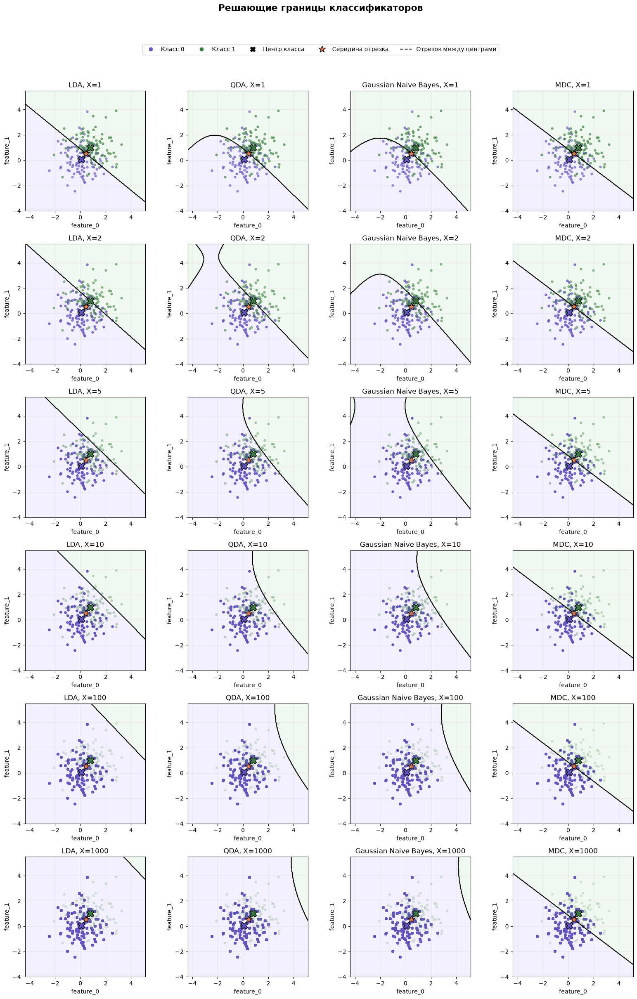

In [12]:
plot_decision_panels(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    show_global_center=False
)

[3.4] Для каждого из решений из пункта [3.3] оценить качество работы полученных на
основе LDA классификаторов, используя ROC и PR кривые и восстановив на графике
кривых соответствующие каждому решению 95% доверительные полосы (Confidence
bands 95%) ROC кривой бутстрепом (n=100 или больше). Для каждой кривой численно
также отобразить метрику AUROС и ее доверительные интервалы CI95. Отдельно
вывести графики сравнения ROC кривых всех классификаторов - LDA, QDA, GNB, MDC.
                       
                                    
Все полученные графики возможно расположить в четыре колонки: левая колонка – визуализация пространства и
решений LDA для отдельного dfrX, следующая – соответствующий этому dfrX и LDA AUROC c доверительной
полосой и бутстреп линиями на одном рисунке, следующая – соответствующий этому dfrX и LDA AUPRC c
доверительной полосой и бутстреп линиями на одном рисунке, правая – соответствующие этому dfrX графики с
ROC кривой для всех классификаторов LDA, QDA, GNB, MDC и их доверительными полосами на одном рисунке (без
отображения линий бутстрепа).

In [13]:
def bootstrap_curves(y, scores, n_boot=500, n_grid=200, seed=42):
    rng = np.random.default_rng(seed)
    specificity_grid = np.linspace(0, 1, n_grid)
    recall_grid = np.linspace(0, 1, n_grid)

    roc_curves, pr_curves = [], []
    roc_aucs, pr_aucs = [], []

    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        yb, sb = y[idx], scores[idx]

        if len(np.unique(yb)) < 2:
            continue

        fpr, tpr, _ = roc_curve(yb, sb)
        specificity = 1 - fpr

        roc_curves.append(
            np.interp(specificity_grid, specificity[::-1], tpr[::-1])
        )
        roc_aucs.append(auc(fpr, tpr))

        precision, recall, _ = precision_recall_curve(yb, sb)
        pr_curves.append(
            np.interp(recall_grid, recall[::-1], precision[::-1])
        )
        pr_aucs.append(auc(recall[::-1], precision[::-1]))

    return {
        'specificity_grid': specificity_grid,
        'roc_curves': np.array(roc_curves),
        'roc_aucs': np.array(roc_aucs),
        'recall_grid': recall_grid,
        'pr_curves': np.array(pr_curves),
        'pr_aucs': np.array(pr_aucs)
    }


def plot_3_4_panels(
    datasets,
    selected_classes,
    features,
    target_class,
    class_col='class',
    n_boot=500,
    n_boot_display=30,
    test_size=0.3,
    random_state=42,
    grid_size=250,
    figsize=None,
    show_global_center=True
):
    negative_class = next(c for c in selected_classes if c != target_class)

    colors = {
        negative_class: '#6453C5',
        target_class: '#3B7E3F'
    }
    region_colors = ['#DCD6F7', '#D5F0D5']
    palette = {
        'LDA': '#1f77b4',
        'QDA': '#ff7f0e',
        'GNB': '#2ca02c',
        'MDC': '#d62728'
    }

    n_rows = len(datasets)
    if figsize is None:
        figsize = (20, 5 * n_rows)

    fig, axes = plt.subplots(n_rows, 4, figsize=figsize, squeeze=False)
    prepared = []

    for row, (X_repeat, dfrX) in enumerate(datasets.items()):
        data = dfrX[
            dfrX[class_col].isin(selected_classes)
        ][features + [class_col]].dropna()

        X_all = data[features].to_numpy()
        y_all = (data[class_col].to_numpy() == target_class).astype(int)

        X_train, X_test, y_train, y_test = train_test_split(
            X_all, y_all,
            test_size=test_size,
            random_state=random_state,
            stratify=y_all
        )

        centers = {
            cls: data.loc[data[class_col] == cls, features].mean().to_numpy()
            for cls in selected_classes
        }
        midpoint = (centers[negative_class] + centers[target_class]) / 2
        global_center = data[features].mean().to_numpy()

        mdc_centers = {
            0: X_train[y_train == 0].mean(axis=0),
            1: X_train[y_train == 1].mean(axis=0)
        }

        models = {
            'LDA': LinearDiscriminantAnalysis(),
            'QDA': QuadraticDiscriminantAnalysis(),
            'GNB': GaussianNB()
        }

        scores = {}

        for name, model in models.items():
            model.fit(X_train, y_train)
            scores[name] = model.predict_proba(X_test)[:, 1]

        dist_negative = np.sum((X_test - mdc_centers[0]) ** 2, axis=1)
        dist_positive = np.sum((X_test - mdc_centers[1]) ** 2, axis=1)
        scores['MDC'] = dist_negative - dist_positive

        prepared.append({
            'repeat': X_repeat,
            'data': data,
            'X_train': X_train,
            'X_test': X_test,
            'y_test': y_test,
            'centers': centers,
            'midpoint': midpoint,
            'global_center': global_center,
            'models': models,
            'scores': scores
        })

    total_boot = len(prepared) * 4 * n_boot
    all_boot = []

    with tqdm(total=total_boot, desc='Bootstrap') as pbar:
        for row, item in enumerate(prepared):
            boot = {}

            for i, (name, score) in enumerate(item['scores'].items()):
                result = bootstrap_curves(
                    item['y_test'],
                    score,
                    n_boot=n_boot,
                    seed=random_state + row * 10 + i
                )
                boot[name] = result
                pbar.update(n_boot)

            all_boot.append(boot)

    for row, item in enumerate(prepared):
        X_repeat = item['repeat']
        data = item['data']
        y_test = item['y_test']
        centers = item['centers']
        midpoint = item['midpoint']
        global_center = item['global_center']
        models = item['models']
        scores = item['scores']
        boot = all_boot[row]

        ax = axes[row, 0]

        x_min, x_max = data[features[0]].min(), data[features[0]].max()
        y_min, y_max = data[features[1]].min(), data[features[1]].max()
        x_center = (x_min + x_max) / 2
        y_center = (y_min + y_max) / 2

        half_range = max(
            (x_max - x_min) / 2,
            (y_max - y_min) / 2
        ) * 1.5

        xx, yy = np.meshgrid(
            np.linspace(x_center - half_range, x_center + half_range, grid_size),
            np.linspace(y_center - half_range, y_center + half_range, grid_size)
        )
        grid = np.c_[xx.ravel(), yy.ravel()]
        Z = models['LDA'].predict(grid).reshape(xx.shape)

        ax.contourf(
            xx, yy, Z,
            levels=[-0.5, 0.5, 1.5],
            colors=region_colors,
            alpha=0.35
        )
        ax.contour(
            xx, yy, Z,
            levels=[0.5],
            colors='black',
            linewidths=1.5
        )

        point_alpha = np.clip(0.5 / np.sqrt(len(data) / 300), 0.15, 0.7)

        for cls in selected_classes:
            class_data = data[data[class_col] == cls]

            ax.scatter(
                class_data[features[0]],
                class_data[features[1]],
                color=colors[cls],
                s=12,
                alpha=point_alpha,
                rasterized=True
            )

            ax.scatter(
                *centers[cls],
                color=colors[cls],
                marker='X',
                s=140,
                edgecolor='black',
                linewidth=1,
                zorder=5
            )

        ax.plot(
            [centers[negative_class][0], centers[target_class][0]],
            [centers[negative_class][1], centers[target_class][1]],
            color='black',
            linestyle='--',
            linewidth=1.5
        )

        ax.scatter(
            *midpoint,
            color='#E87950',
            marker='*',
            s=180,
            edgecolor='black',
            linewidth=0.8,
            zorder=6
        )

        if show_global_center:
            ax.scatter(
                *global_center,
                color='red',
                marker='s',
                s=30,
                edgecolor='black',
                linewidth=0.7,
                zorder=7
            )

        ax.set_title(f'dfr{X_repeat}: решающая область LDA')
        ax.set_xlabel(features[0])
        ax.set_ylabel(features[1])
        ax.grid(alpha=0.2)
        ax.set_aspect('equal', adjustable='box')

        ax = axes[row, 1]
        score = scores['LDA']
        r = boot['LDA']

        fpr, tpr, _ = roc_curve(y_test, score)
        auc_value = auc(fpr, tpr)
        auc_ci = np.percentile(r['roc_aucs'], [2.5, 97.5])
        lo, hi = np.percentile(r['roc_curves'], [2.5, 97.5], axis=0)

        ax.fill_between(
            r['specificity_grid'], lo, hi,
            color=palette['LDA'],
            alpha=0.2,
            label='95% CI band'
        )

        for curve in r['roc_curves'][:n_boot_display]:
            ax.plot(
                r['specificity_grid'], curve,
                color=palette['LDA'],
                alpha=0.2,
                linewidth=0.7
            )

        ax.plot(
            1 - fpr, tpr,
            color=palette['LDA'],
            linewidth=2,
            label=f'AUROC={auc_value:.3f}; CI [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]'
        )
        ax.plot([1, 0], [0, 1], 'k--', linewidth=0.7, label='Baseline')
        ax.set_title(f'dfr{X_repeat}: ROC LDA')
        ax.set_xlabel('Specificity')
        ax.set_ylabel('Sensitivity')
        ax.set_xlim(1, 0)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.2)
        ax.set_box_aspect(1)
        ax.legend(fontsize=8)

        ax = axes[row, 2]
        precision, recall, _ = precision_recall_curve(y_test, score)
        recall, precision = recall[::-1], precision[::-1]

        auprc_value = auc(recall, precision)
        pr_ci = np.percentile(r['pr_aucs'], [2.5, 97.5])
        lo, hi = np.percentile(r['pr_curves'], [2.5, 97.5], axis=0)

        ax.fill_between(
            r['recall_grid'], lo, hi,
            color='#ff7f0e',
            alpha=0.2,
            label='95% CI band'
        )

        for curve in r['pr_curves'][:n_boot_display]:
            ax.plot(
                r['recall_grid'], curve,
                color='#ff7f0e',
                alpha=0.2,
                linewidth=0.7
            )

        ax.plot(
            recall, precision,
            color='#ff7f0e',
            linewidth=2,
            label=f'AUPRC={auprc_value:.3f}; CI [{pr_ci[0]:.3f}, {pr_ci[1]:.3f}]'
        )
        ax.axhline(
            np.mean(y_test),
            color='black',
            linestyle='--',
            linewidth=0.7,
            label='Baseline'
        )
        ax.set_title(f'dfr{X_repeat}: PR LDA')
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.2)
        ax.set_box_aspect(1)
        ax.legend(fontsize=8)

        ax = axes[row, 3]

        for name, score in scores.items():
            r = boot[name]
            fpr, tpr, _ = roc_curve(y_test, score)

            auc_value = auc(fpr, tpr)
            auc_ci = np.percentile(r['roc_aucs'], [2.5, 97.5])
            lo, hi = np.percentile(r['roc_curves'], [2.5, 97.5], axis=0)

            ax.fill_between(
                r['specificity_grid'], lo, hi,
                color=palette[name],
                alpha=0.12
            )

            ax.plot(
                1 - fpr, tpr,
                color=palette[name],
                linewidth=1.8,
                label=f'{name}: AUC={auc_value:.3f} [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]'
            )

        ax.plot([1, 0], [0, 1], 'k--', linewidth=0.7, label='Baseline')
        ax.set_title(f'dfr{X_repeat}: сравнение ROC')
        ax.set_xlabel('Specificity')
        ax.set_ylabel('Sensitivity')
        ax.set_xlim(1, 0)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.2)
        ax.set_box_aspect(1)
        ax.legend(fontsize=7, loc='lower left')

    legend_elements = [
        Line2D(
            [0], [0], marker='o', color='w',
            markerfacecolor=colors[cls], markersize=8,
            label=f'Класс {cls}'
        )
        for cls in selected_classes
    ]

    legend_elements += [
        Line2D(
            [0], [0], marker='X', color='black',
            linestyle='None', markersize=9,
            label='Центр класса'
        ),
        Line2D(
            [0], [0], marker='*', color='#E87950',
            markeredgecolor='black', linestyle='None',
            markersize=12, label='Середина отрезка'
        ),
        Line2D(
            [0], [0], color='black', linestyle='--',
            label='Отрезок между центрами'
        )
    ]

    if show_global_center:
        legend_elements.append(
            Line2D(
                [0], [0], marker='s', color='w',
                markerfacecolor='red', markeredgecolor='black',
                markersize=6, linestyle='None',
                label='Общий центр масс'
            )
        )

    fig.legend(
        handles=legend_elements,
        loc='upper center',
        ncol=min(len(legend_elements), 6),
        bbox_to_anchor=(0.5, 1.01)
    )

    fig.suptitle(
        f'Классификация классов {negative_class} и {target_class}',
        fontsize=16,
        fontweight='bold',
        y=1.04
    )
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

Bootstrap: 100%|██████████| 12000/12000 [00:24<00:00, 480.86it/s]


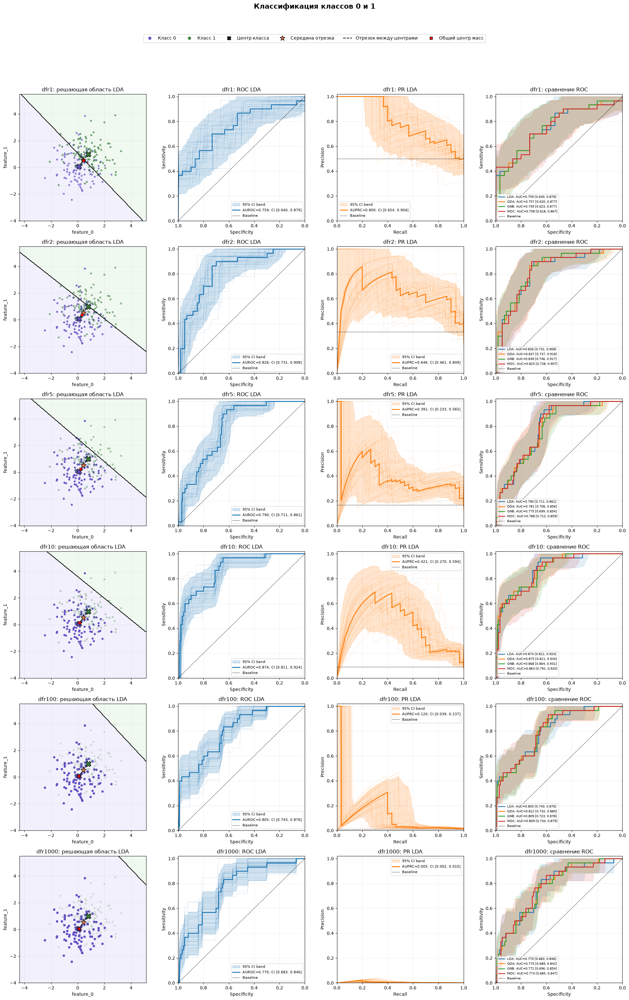

In [14]:
plot_3_4_panels(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    target_class=1,
    class_col='class',
    n_boot=500,
    n_boot_display=30
)

[3.5] Выбрать другой целевой класс и повторить визуализации пунктов [3.3-3.4].

Построение графиков: 100%|██████████| 24/24 [00:00<00:00, 39.90it/s]


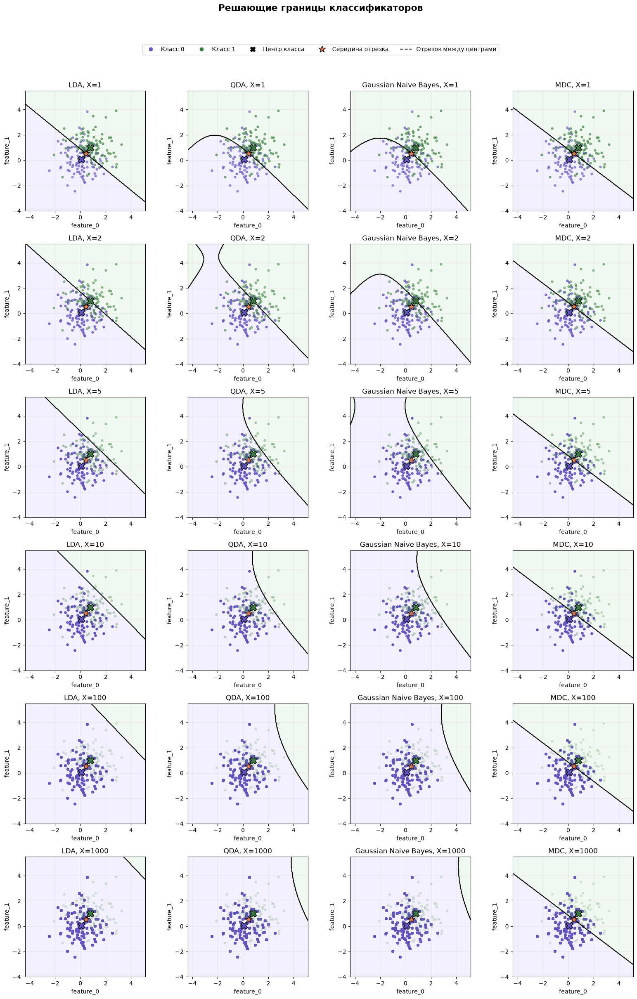

In [15]:
plot_decision_panels(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    show_global_center=False
)

Bootstrap: 100%|██████████| 12000/12000 [00:25<00:00, 479.25it/s]


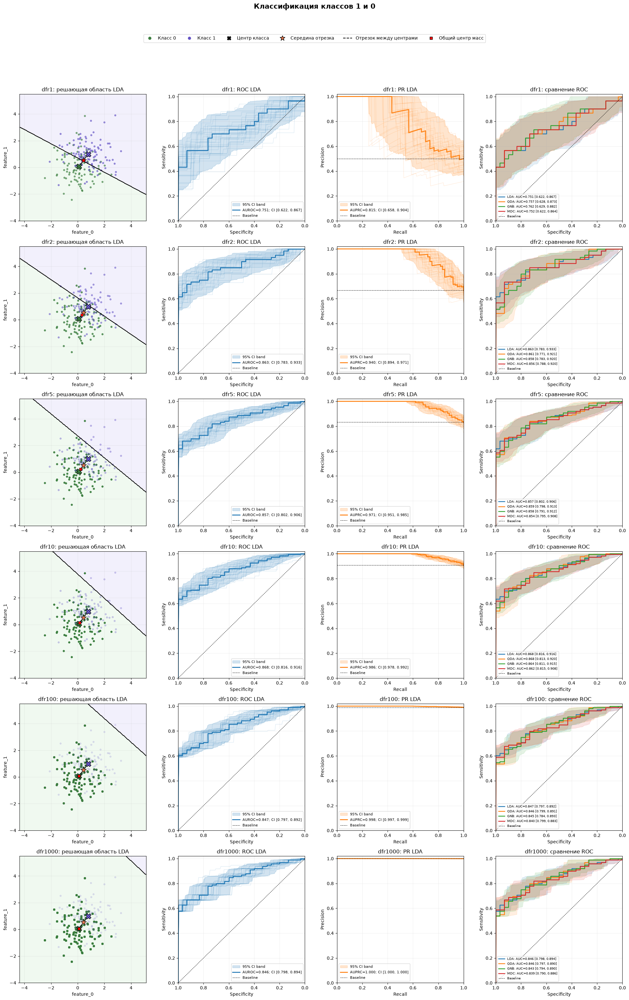

In [16]:
plot_3_4_panels(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    target_class=0,
    class_col='class',
    n_boot=500,
    n_boot_display=30
)

[3.6] Для датасета dfr10 на основе 3-fold, 5-fold, 10-fold, 20-fold, 50-fold, 100-fold кросс-
валидации построить кривые AUROC и AUPRC c 95% доверительными полосами (CI95),
выведя каждую кривую AUROC и AUPRC со всеми линиями кросс-валидации и c 95%
доверительными полосами (CI95) как отдельный график. # Вместо CI95 можно взять CI90, CI80
или другой квантиль доверительной полосы.

In [17]:
def plot_cv_curves(
    dfr10,
    features,
    class_col='class',
    target_class=1,
    n_boot=1000,
    ci=95,
    seed=42
):
    if not 0 < ci < 100:
        raise ValueError("ci должен быть между 0 и 100.")

    data = dfr10[features + [class_col]].dropna()

    X = data[features].to_numpy()
    y = (data[class_col].to_numpy() == target_class).astype(int)

    folds_list = [3, 5, 10, 20, 50, 100]

    counts = np.bincount(y, minlength=2)
    if counts.min() < max(folds_list):
        raise ValueError(
            f"Для 100-fold нужно не менее 100 объектов каждого класса. "
            f"Сейчас: отрицательный класс — {counts[0]}, "
            f"целевой класс — {counts[1]}."
        )

    model = LinearDiscriminantAnalysis()

    tail = (100 - ci) / 2
    ci_low = tail
    ci_high = 100 - tail

    for n_splits in folds_list:
        cv = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        roc_results = []
        pr_results = []
        roc_aucs = []
        pr_aucs = []

        fpr_grid = np.linspace(0, 1, 200)
        specificity_grid = np.linspace(0, 1, 200)
        recall_grid = np.linspace(0, 1, 200)

        for train_idx, test_idx in tqdm(
            cv.split(X, y),
            total=n_splits,
            desc=f'{n_splits}-fold'
        ):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            fitted_model = clone(model)
            fitted_model.fit(X_train, y_train)

            scores = fitted_model.predict_proba(X_test)[:, 1]

            fpr, tpr, _ = roc_curve(y_test, scores)
            specificity = 1 - fpr

            roc_results.append(
                np.interp(
                    specificity_grid,
                    specificity[::-1],
                    tpr[::-1]
                )
            )
            roc_aucs.append(auc(fpr, tpr))

            precision, recall, _ = precision_recall_curve(
                y_test, scores
            )

            pr_results.append(
                np.interp(
                    recall_grid,
                    recall[::-1],
                    precision[::-1]
                )
            )
            pr_aucs.append(auc(recall[::-1], precision[::-1]))

        roc_results = np.asarray(roc_results)
        pr_results = np.asarray(pr_results)
        roc_aucs = np.asarray(roc_aucs)
        pr_aucs = np.asarray(pr_aucs)

        roc_mean = roc_results.mean(axis=0)
        pr_mean = pr_results.mean(axis=0)

        rng = np.random.default_rng(seed + n_splits)

        roc_boot = np.empty((n_boot, len(specificity_grid)))
        pr_boot = np.empty((n_boot, len(recall_grid)))
        roc_auc_boot = np.empty(n_boot)
        pr_auc_boot = np.empty(n_boot)

        for b in range(n_boot):
            idx = rng.integers(0, n_splits, size=n_splits)

            roc_boot[b] = roc_results[idx].mean(axis=0)
            pr_boot[b] = pr_results[idx].mean(axis=0)

            roc_auc_boot[b] = roc_aucs[idx].mean()
            pr_auc_boot[b] = pr_aucs[idx].mean()

        roc_low, roc_high = np.percentile(
            roc_boot, [ci_low, ci_high], axis=0
        )

        pr_low, pr_high = np.percentile(
            pr_boot, [ci_low, ci_high], axis=0
        )

        roc_auc_mean = roc_aucs.mean()
        pr_auc_mean = pr_aucs.mean()

        roc_auc_ci = np.percentile(
            roc_auc_boot, [ci_low, ci_high]
        )
        pr_auc_ci = np.percentile(
            pr_auc_boot, [ci_low, ci_high]
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        ax = axes[0]

        for curve in roc_results:
            ax.plot(
                specificity_grid, curve,
                color='steelblue', alpha=0.2
            )

        ax.fill_between(
            specificity_grid, roc_low, roc_high,
            color='steelblue', alpha=0.2,
            label=f'CI {ci}%'
        )

        ax.plot(
            specificity_grid, roc_mean,
            color='navy', linewidth=2,
            label=(
                f'AUROC={roc_auc_mean:.3f}; '
                f'CI [{roc_auc_ci[0]:.3f}, {roc_auc_ci[1]:.3f}]'
            )
        )

        ax.plot(
            [1, 0], [0, 1],
            'k--', label='Baseline'
        )

        ax.set(
            title=f'ROC, {n_splits}-fold CV',
            xlabel='Specificity',
            ylabel='Sensitivity',
            xlim=(1, 0),
            ylim=(0, 1)
        )

        ax.grid(alpha=0.2)
        ax.legend()
        ax.set_box_aspect(1)

        ax = axes[1]

        for curve in pr_results:
            ax.plot(
                recall_grid, curve,
                color='darkorange', alpha=0.2
            )

        ax.fill_between(
            recall_grid, pr_low, pr_high,
            color='darkorange', alpha=0.2,
            label=f'CI {ci}%'
        )

        ax.plot(
            recall_grid, pr_mean,
            color='darkred', linewidth=2,
            label=(
                f'AUPRC={pr_auc_mean:.3f}; '
                f'CI [{pr_auc_ci[0]:.3f}, {pr_auc_ci[1]:.3f}]'
            )
        )

        ax.axhline(
            y=y.mean(),
            color='black',
            linestyle='--',
            label='Baseline'
        )

        ax.set(
            title=f'PR, {n_splits}-fold CV',
            xlabel='Recall',
            ylabel='Precision',
            xlim=(0, 1),
            ylim=(0, 1)
        )

        ax.grid(alpha=0.2)
        ax.legend()
        ax.set_box_aspect(1)

        fig.suptitle(
            f'dfr10: {n_splits}-fold CV, CI {ci}%'
        )

        plt.tight_layout()
        plt.show()

3-fold: 100%|██████████| 3/3 [00:00<00:00, 170.94it/s]


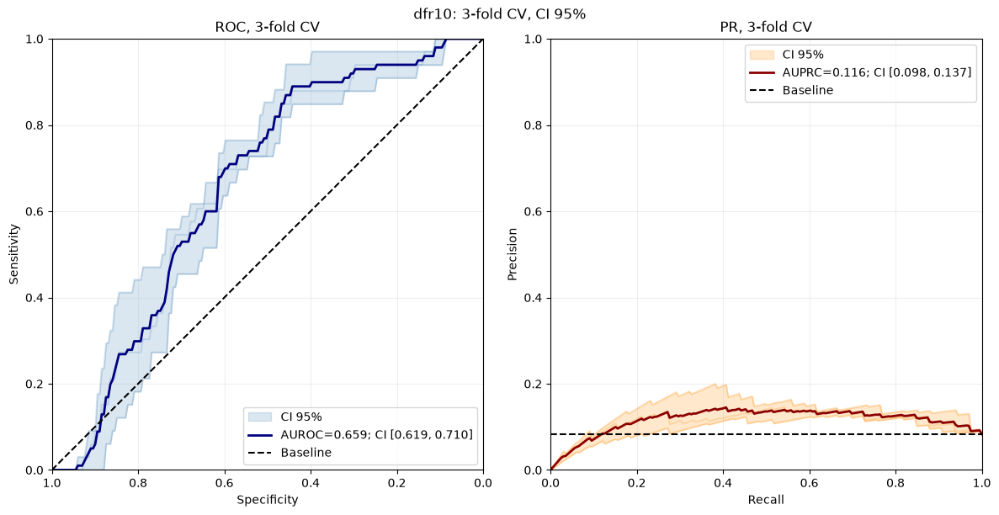

5-fold: 100%|██████████| 5/5 [00:00<00:00, 449.84it/s]


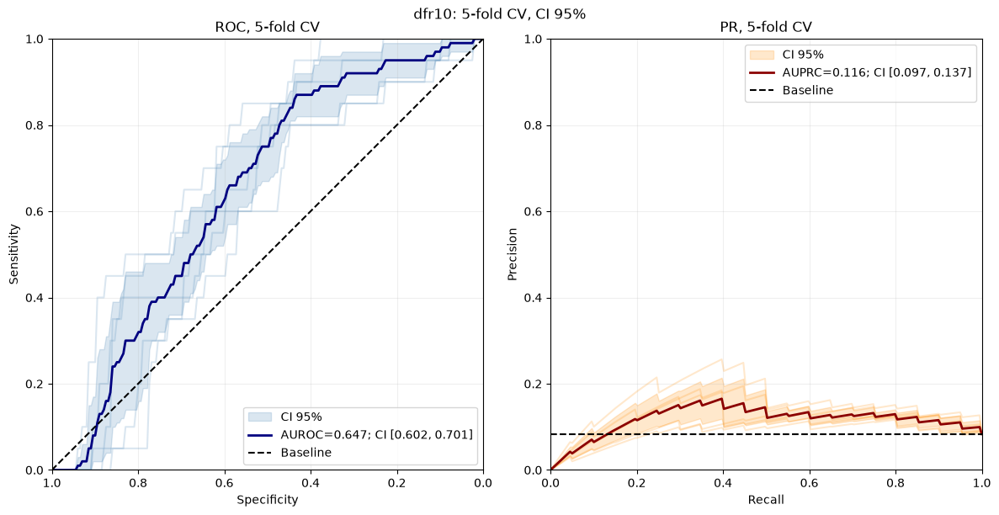

10-fold: 100%|██████████| 10/10 [00:00<00:00, 520.75it/s]


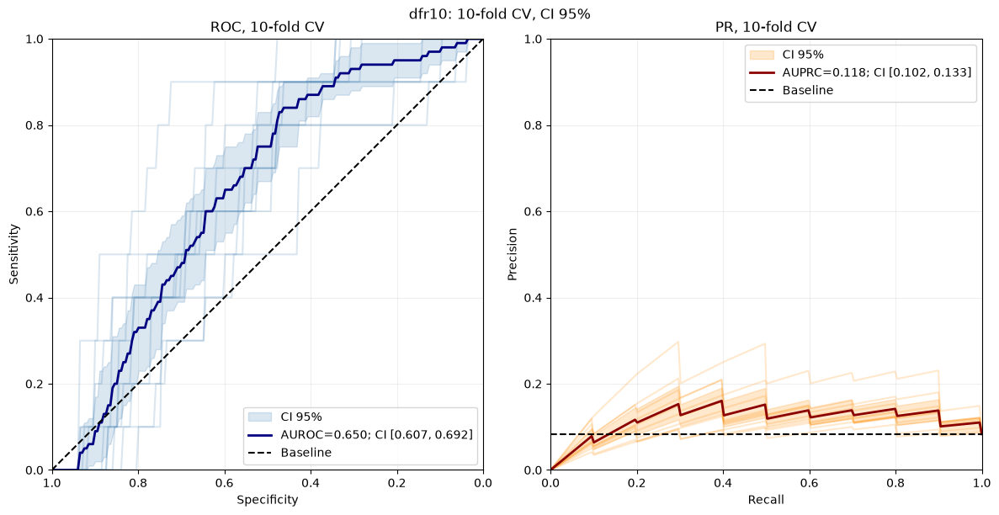

20-fold: 100%|██████████| 20/20 [00:00<00:00, 488.93it/s]


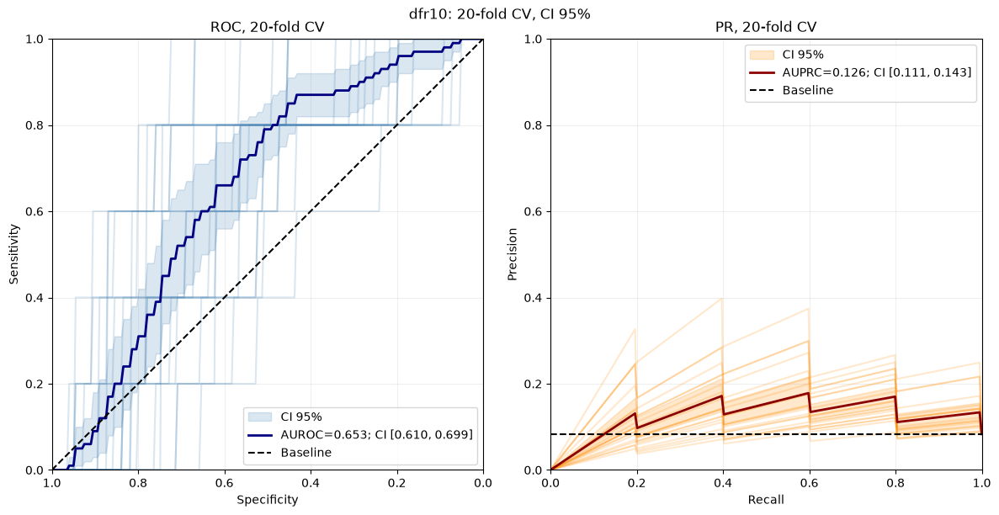

50-fold: 100%|██████████| 50/50 [00:00<00:00, 526.18it/s]


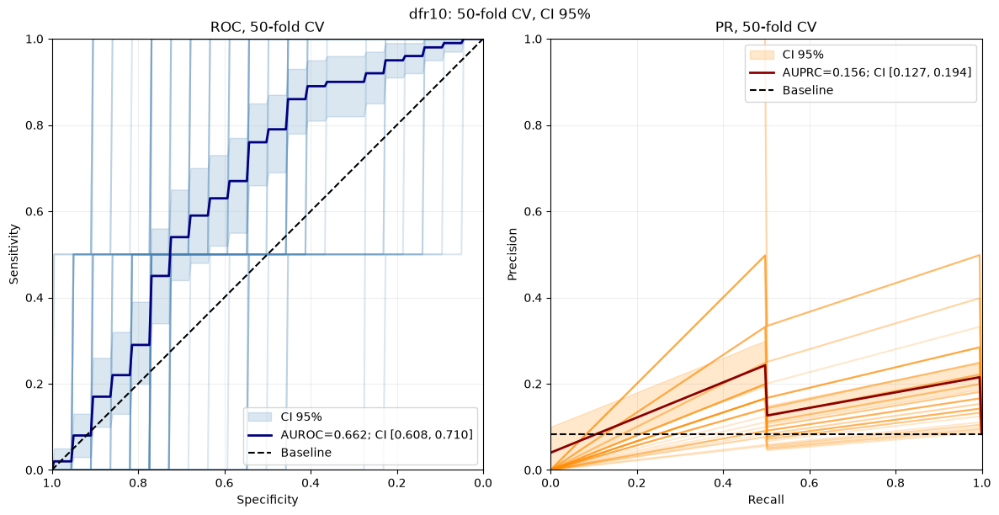

100-fold: 100%|██████████| 100/100 [00:00<00:00, 412.55it/s]


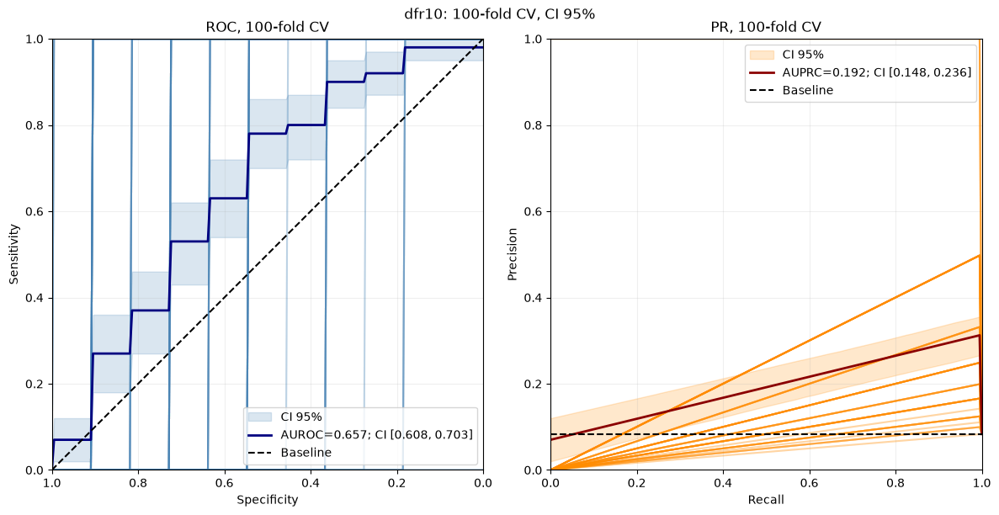

In [18]:
plot_cv_curves(
    dfr10=datasets[10],
    features=['feature_0', 'feature_1'],
    class_col='class',
    target_class=1,
    ci=95
)

[3.7] Для датасета dfr1 построить решения LDA на двух, четырех, восьми и шестнадцати
признаках. Для каждого решения на одном графике восстановить ROC кривые с
доверительными полосами 95%. Аналогично восстановить PR кривые.

In [19]:
def plot_3_7(
    dfr1,
    class_col='class',
    target_class=1,
    n_boot=1000,
    seed=42
):
    feature_counts = [2, 4, 8, 16]

    tail = (100 - 95) / 2
    rng = np.random.default_rng(seed)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

    for i, n_features in enumerate(feature_counts):
        features = [
            col for col in dfr1.columns if col != class_col
        ][:n_features]

        data = dfr1[features + [class_col]].dropna()

        X = data[features].to_numpy()
        y = (data[class_col].to_numpy() == target_class).astype(int)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.3,
            random_state=seed,
            stratify=y
        )

        model = LinearDiscriminantAnalysis()
        model.fit(X_train, y_train)

        scores = model.predict_proba(X_test)[:, 1]

        result = bootstrap_curves(
            y_test,
            scores,
            n_boot=n_boot,
            seed=seed + i
        )

        color = colors[i]

        fpr, tpr, _ = roc_curve(y_test, scores)
        roc_auc = auc(fpr, tpr)
        roc_auc_ci = np.percentile(result['roc_aucs'], [2.5, 97.5])

        roc_low, roc_high = np.percentile(
            result['roc_curves'], [2.5, 97.5], axis=0
        )

        axes[0].fill_between(
            result['specificity_grid'],
            roc_low, roc_high,
            color=color, alpha=0.12
        )

        axes[0].plot(
            1 - fpr, tpr,
            color=color, linewidth=2,
            label=(
                f'{n_features} признака(ов): '
                f'AUROC={roc_auc:.3f}, '
                f'CI [{roc_auc_ci[0]:.3f}, {roc_auc_ci[1]:.3f}]'
            )
        )

        precision, recall, _ = precision_recall_curve(y_test, scores)
        recall_reversed = recall[::-1]
        precision_reversed = precision[::-1]

        pr_auc = auc(recall_reversed, precision_reversed)
        pr_auc_ci = np.percentile(result['pr_aucs'], [2.5, 97.5])

        pr_low, pr_high = np.percentile(
            result['pr_curves'], [2.5, 97.5], axis=0
        )

        axes[1].fill_between(
            result['recall_grid'],
            pr_low, pr_high,
            color=color, alpha=0.12
        )

        axes[1].plot(
            recall_reversed, precision_reversed,
            color=color, linewidth=2,
            label=(
                f'{n_features} признака(ов): '
                f'AUPRC={pr_auc:.3f}, '
                f'CI [{pr_auc_ci[0]:.3f}, {pr_auc_ci[1]:.3f}]'
            )
        )

    axes[0].plot([1, 0], [0, 1], 'k--', label='Baseline')
    axes[0].set(
        title='ROC — LDA, dfr1',
        xlabel='Specificity',
        ylabel='Sensitivity',
        xlim=(1, 0),
        ylim=(0, 1.02)
    )
    axes[0].grid(alpha=0.2)
    axes[0].legend(fontsize=8)
    axes[0].set_box_aspect(1)

    axes[1].axhline(
        y=(dfr1[class_col] == target_class).mean(),
        color='black',
        linestyle='--',
        label='Baseline'
    )
    axes[1].set(
        title='PR — LDA, dfr1',
        xlabel='Recall',
        ylabel='Precision',
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    axes[1].grid(alpha=0.2)
    axes[1].legend(fontsize=8)
    axes[0].set_box_aspect(1)

    plt.tight_layout()
    plt.show()

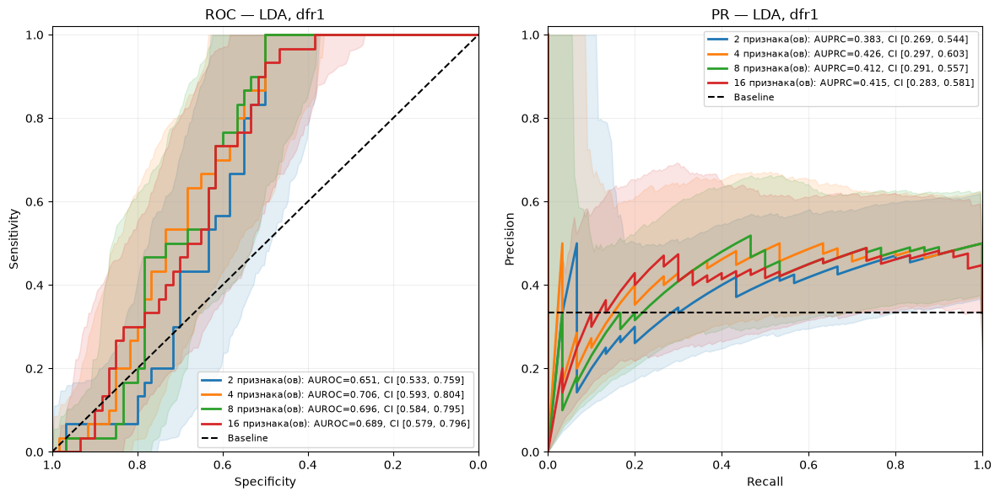

In [20]:
plot_3_7(
    dfr1=datasets[1],
    class_col='class',
    target_class=1
)

[3.8*] Повторить пункт [3.3] для набора алгоритмов LDA, MDC, линейного SVM, LogReg.           
Повторить пункт [3.4] для алгоритма линейного SVM, сравнив его с LDA, MDC, LogReg.

In [21]:
def plot_3_8_curves(
    datasets,
    selected_classes,
    features,
    target_class=1,
    class_col='class',
    n_boot=500,
    test_size=0.3,
    random_state=42
):
    negative_class = next(
        c for c in selected_classes if c != target_class
    )

    palette = {
        'LDA': 'tab:blue',
        'MDC': 'tab:green',
        'Linear SVM': 'tab:red',
        'LogReg': 'tab:orange'
    }

    models = {
        'LDA': LinearDiscriminantAnalysis(),
        'Linear SVM': SVC(kernel='linear'),
        'LogReg': LogisticRegression(max_iter=1000)
    }

    with tqdm(
        total=len(datasets) * 4 * n_boot,
        desc='Bootstrap для пункта 3.8'
    ) as progress:

        for X_repeat, dfrX in datasets.items():
            data = dfrX[
                dfrX[class_col].isin(selected_classes)
            ][features + [class_col]].dropna()

            X = data[features].to_numpy()
            y = (
                data[class_col].to_numpy() == target_class
            ).astype(int)

            X_train, X_test, y_train, y_test = train_test_split(
                X, y,
                test_size=test_size,
                random_state=random_state,
                stratify=y
            )

            scores = {}

            for name, model in models.items():
                model.fit(X_train, y_train)

                if name == 'Linear SVM':
                    scores[name] = model.decision_function(X_test)
                else:
                    scores[name] = model.predict_proba(X_test)[:, 1]

            center_negative = X_train[y_train == 0].mean(axis=0)
            center_positive = X_train[y_train == 1].mean(axis=0)

            dist_negative = np.sum(
                (X_test - center_negative) ** 2, axis=1
            )
            dist_positive = np.sum(
                (X_test - center_positive) ** 2, axis=1
            )

            scores['MDC'] = dist_negative - dist_positive

            boot = {}

            for i, (name, score) in enumerate(scores.items()):
                boot[name] = bootstrap_curves(
                    y_test,
                    score,
                    n_boot=n_boot,
                    seed=random_state + X_repeat + i
                )
                progress.update(n_boot)

            # ROC и PR для линейного SVM
            result = boot['Linear SVM']
            fpr, tpr, _ = roc_curve(
                y_test, scores['Linear SVM']
            )
            precision, recall, _ = precision_recall_curve(
                y_test, scores['Linear SVM']
            )

            recall = recall[::-1]
            precision = precision[::-1]

            roc_ci = np.percentile(
                result['roc_aucs'], [2.5, 97.5]
            )
            pr_ci = np.percentile(
                result['pr_aucs'], [2.5, 97.5]
            )

            roc_low, roc_high = np.percentile(
                result['roc_curves'], [2.5, 97.5], axis=0
            )
            pr_low, pr_high = np.percentile(
                result['pr_curves'], [2.5, 97.5], axis=0
            )

            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            ax = axes[0]
            ax.fill_between(
                result['specificity_grid'],
                roc_low, roc_high,
                color=palette['Linear SVM'],
                alpha=0.2,
                label='95% CI'
            )
            ax.plot(
                1 - fpr, tpr,
                color=palette['Linear SVM'],
                linewidth=2,
                label=(
                    f'AUROC={auc(fpr, tpr):.3f}; '
                    f'CI [{roc_ci[0]:.3f}, {roc_ci[1]:.3f}]'
                )
            )
            ax.plot([1, 0], [0, 1], 'k--', label='Baseline')
            ax.set(
                title=f'dfr{X_repeat}: ROC — Linear SVM',
                xlabel='Specificity',
                ylabel='Sensitivity',
                xlim=(1, 0),
                ylim=(0, 1.02)
            )
            ax.grid(alpha=0.2)
            ax.legend(fontsize=8)
            ax.set_box_aspect(1)

            ax = axes[1]
            ax.fill_between(
                result['recall_grid'],
                pr_low, pr_high,
                color=palette['Linear SVM'],
                alpha=0.2,
                label='95% CI'
            )
            ax.plot(
                recall, precision,
                color=palette['Linear SVM'],
                linewidth=2,
                label=(
                    f'AUPRC={auc(recall, precision):.3f}; '
                    f'CI [{pr_ci[0]:.3f}, {pr_ci[1]:.3f}]'
                )
            )
            ax.axhline(y=y_test.mean(), color='black',
                       linestyle='--', label='Baseline')
            ax.set(
                title=f'dfr{X_repeat}: PR — Linear SVM',
                xlabel='Recall',
                ylabel='Precision',
                xlim=(0, 1),
                ylim=(0, 1.02)
            )
            ax.grid(alpha=0.2)
            ax.legend(fontsize=8)
            ax.set_box_aspect(1)

            ax = axes[2]

            for name, score in scores.items():
                result = boot[name]
                fpr_model, tpr_model, _ = roc_curve(y_test, score)

                auc_ci = np.percentile(
                    result['roc_aucs'], [2.5, 97.5]
                )
                low, high = np.percentile(
                    result['roc_curves'], [2.5, 97.5], axis=0
                )

                ax.fill_between(
                    result['specificity_grid'],
                    low, high,
                    color=palette[name],
                    alpha=0.1
                )
                ax.plot(
                    1 - fpr_model, tpr_model,
                    color=palette[name],
                    linewidth=1.8,
                    label=(
                        f'{name}: AUC={auc(fpr_model, tpr_model):.3f} '
                        f'[{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]'
                    )
                )

            ax.plot([1, 0], [0, 1], 'k--', label='Baseline')
            ax.set(
                title=f'dfr{X_repeat}: сравнение ROC',
                xlabel='Specificity',
                ylabel='Sensitivity',
                xlim=(1, 0),
                ylim=(0, 1.02)
            )
            ax.grid(alpha=0.2)
            ax.legend(fontsize=7)
            ax.set_box_aspect(1)

            plt.tight_layout()
            plt.show()

Построение графиков: 100%|██████████| 24/24 [00:01<00:00, 17.18it/s]


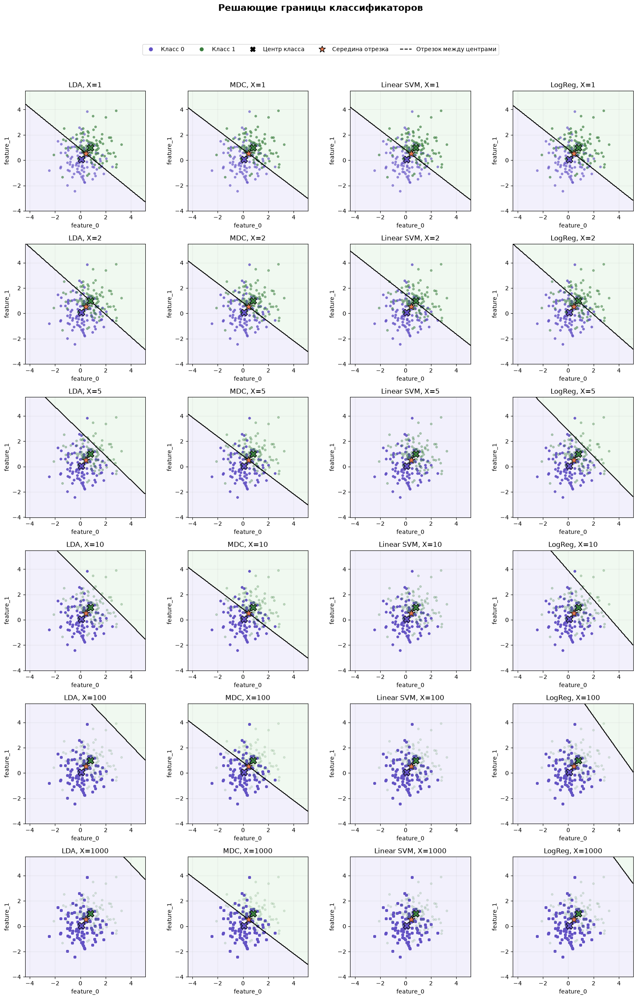

In [22]:
plot_decision_panels(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    methods=('LDA', 'MDC', 'Linear SVM', 'LogReg'),
    show_global_center=False
)

Bootstrap для пункта 3.8:  17%|█▋        | 2000/12000 [00:01<00:09, 1078.77it/s]

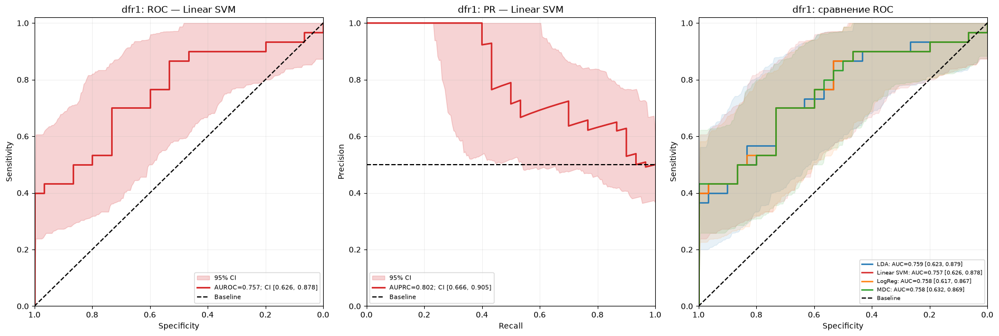

Bootstrap для пункта 3.8:  33%|███▎      | 4000/12000 [00:04<00:08, 981.99it/s] 

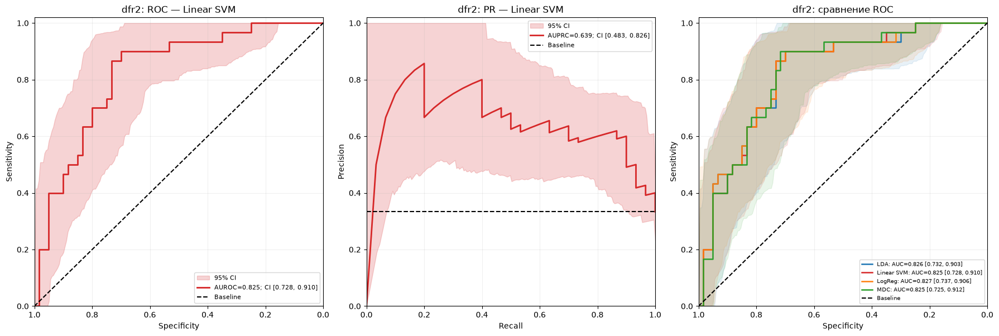

Bootstrap для пункта 3.8:  50%|█████     | 6000/12000 [00:06<00:06, 921.69it/s]

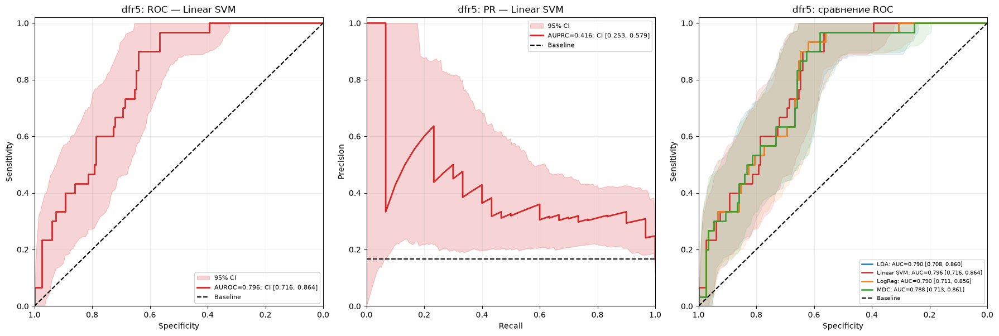

Bootstrap для пункта 3.8:  67%|██████▋   | 8000/12000 [00:08<00:04, 955.66it/s]

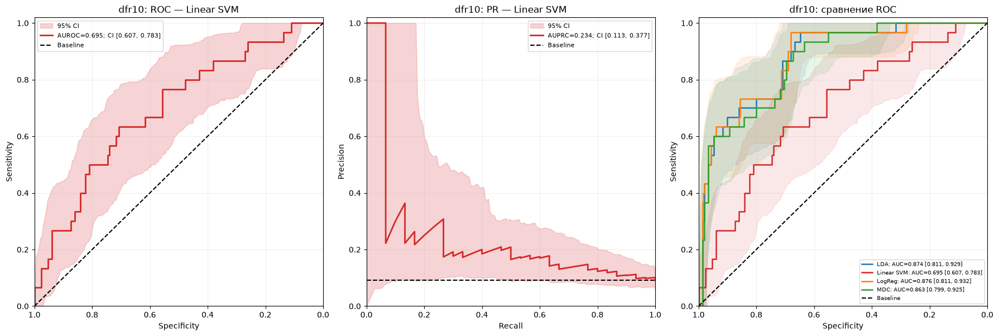

Bootstrap для пункта 3.8:  83%|████████▎ | 10000/12000 [00:11<00:02, 711.53it/s]

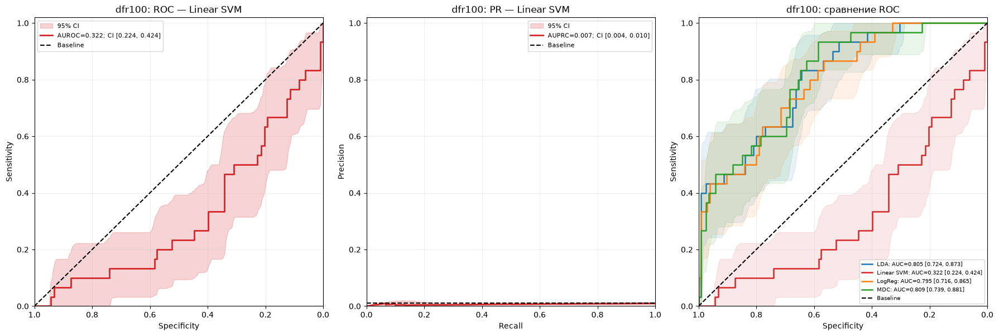

Bootstrap для пункта 3.8: 100%|██████████| 12000/12000 [00:26<00:00, 167.91it/s]

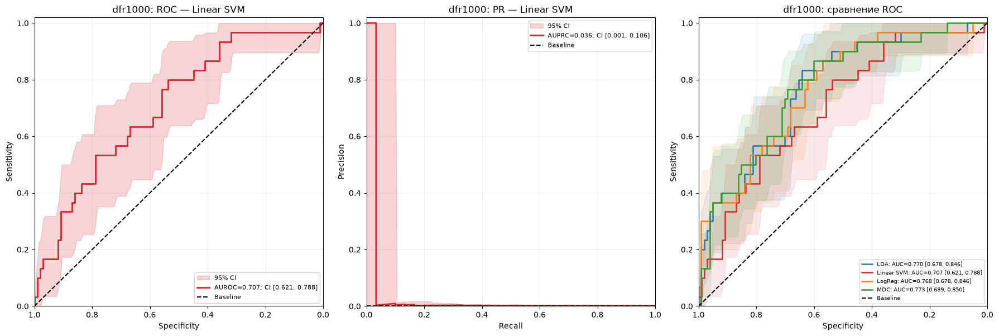

Bootstrap для пункта 3.8: 100%|██████████| 12000/12000 [00:27<00:00, 440.80it/s]


In [23]:
plot_3_8_curves(
    datasets=datasets,
    selected_classes=[0, 1],
    features=['feature_0', 'feature_1'],
    target_class=1,
    n_boot=500
)